In [1]:
import numpy as np
import pandas as pd
import yfinance as yf
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, coint
import matplotlib.pyplot as plt


In [2]:
tickers = ["EWA", "EWC"]

data = yf.download(
    tickers,
    start="2006-01-01",
    auto_adjust=True,
    progress=False
)

prices = data["Close"][tickers].dropna()

print(prices.head())

Ticker           EWA        EWC
Date                           
2006-01-03  7.777655  15.002355
2006-01-04  7.891134  15.182789
2006-01-05  7.878974  14.955573
2006-01-06  7.964087  15.102588
2006-01-09  7.964087  14.995673


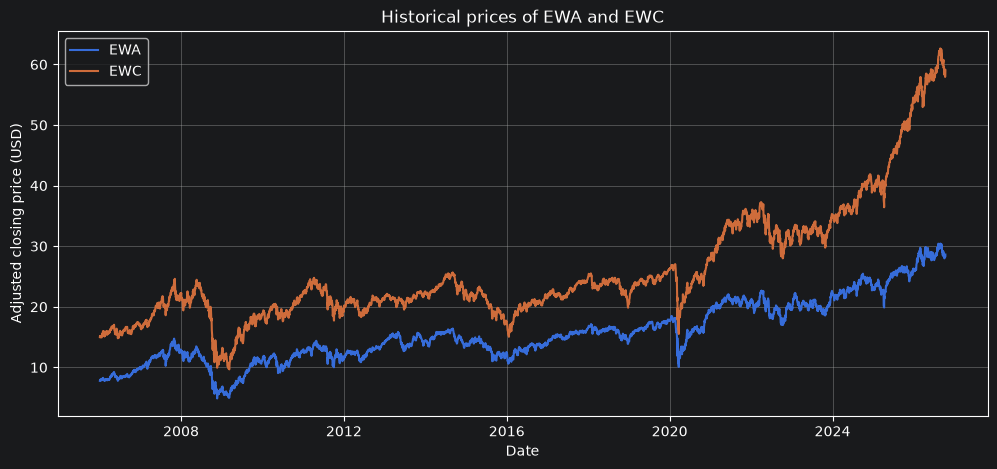

In [3]:
plt.figure(figsize=(12, 5))

plt.plot(prices.index, prices["EWA"], label="EWA")
plt.plot(prices.index, prices["EWC"], label="EWC")

plt.xlabel("Date")
plt.ylabel("Adjusted closing price (USD)")
plt.title("Historical prices of EWA and EWC")
plt.legend()
plt.grid(True)
plt.show()

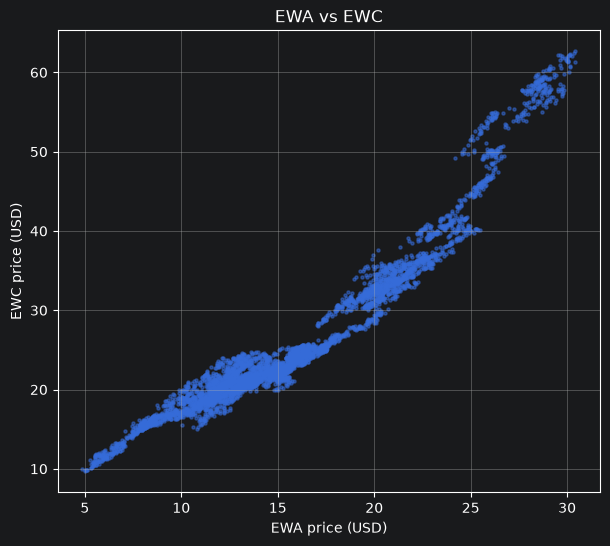

In [4]:
plt.figure(figsize=(7, 6))

plt.scatter(prices["EWA"], prices["EWC"], s=5, alpha=0.5)

plt.xlabel("EWA price (USD)")
plt.ylabel("EWC price (USD)")
plt.title("EWA vs EWC")
plt.grid(True)
plt.show()

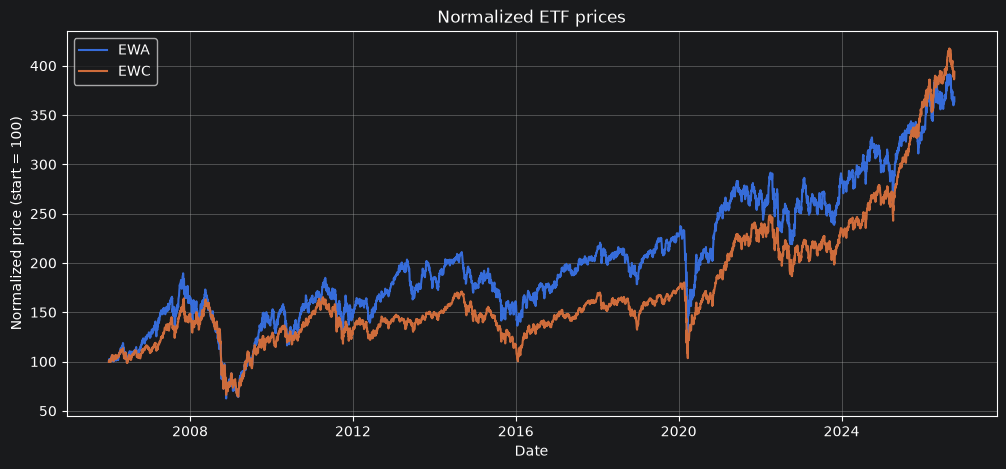

In [5]:
normalized = prices / prices.iloc[0] * 100

plt.figure(figsize=(12, 5))

plt.plot(normalized.index, normalized["EWA"], label="EWA")
plt.plot(normalized.index, normalized["EWC"], label="EWC")

plt.xlabel("Date")
plt.ylabel("Normalized price (start = 100)")
plt.title("Normalized ETF prices")
plt.legend()
plt.grid(True)
plt.show()

In [6]:
import statsmodels.api as sm

# Training period
train = prices.loc["2006-01-01":"2012-12-31"]

# Independent variable: EWA
X = sm.add_constant(train["EWA"])

# Dependent variable: EWC
y = train["EWC"]

# Estimate OLS regression
model = sm.OLS(y, X).fit()

# Extract coefficients
alpha = model.params["const"]
beta = model.params["EWA"]

print(f"Intercept: {alpha:.4f}")
print(f"Hedge ratio: {beta:.4f}")
print(model.summary())

Intercept: 3.8410
Hedge ratio: 1.3937
                            OLS Regression Results                            
Dep. Variable:                    EWC   R-squared:                       0.905
Model:                            OLS   Adj. R-squared:                  0.905
Method:                 Least Squares   F-statistic:                 1.671e+04
Date:                Sun, 11 Oct 2026   Prob (F-statistic):               0.00
Time:                        08:34:53   Log-Likelihood:                -2456.4
No. Observations:                1761   AIC:                             4917.
Df Residuals:                    1759   BIC:                             4928.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         

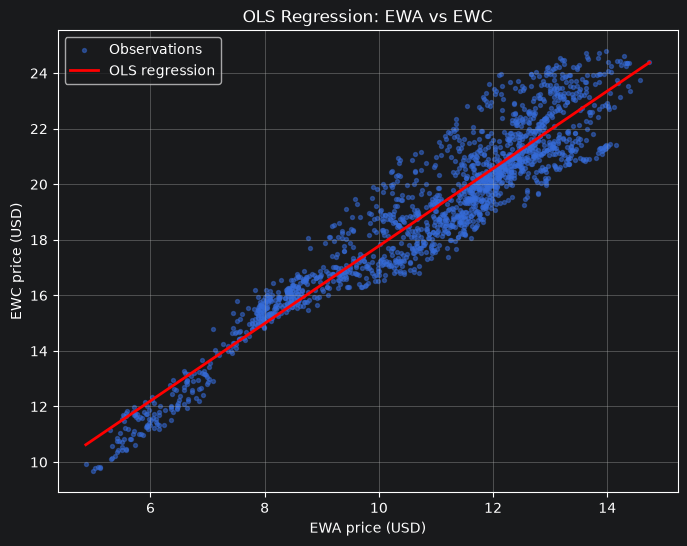

In [7]:
import numpy as np

x_line = np.linspace(train["EWA"].min(), train["EWA"].max(), 100)
y_line = alpha + beta * x_line

plt.figure(figsize=(8, 6))

plt.scatter(train["EWA"], train["EWC"],
            s=8, alpha=0.5, label="Observations")

plt.plot(x_line, y_line, color="red",
         linewidth=2, label="OLS regression")

plt.xlabel("EWA price (USD)")
plt.ylabel("EWC price (USD)")
plt.title("OLS Regression: EWA vs EWC")
plt.legend()
plt.grid(True)
plt.show()

#Plot looks very different from first scatter plot because here we take only data from 2006-2012.

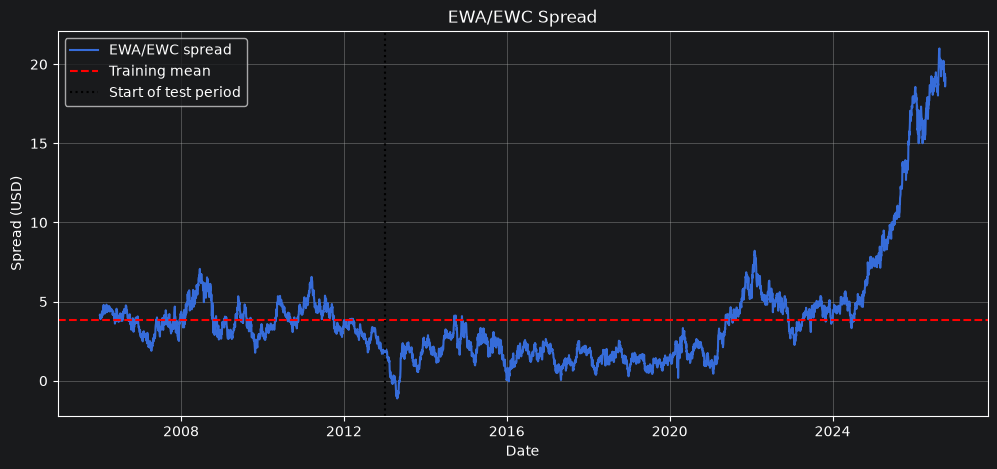

In [8]:
# Construct the spread using the estimated hedge ratio
spread = prices["EWC"] - beta * prices["EWA"]

# Plot the spread
plt.figure(figsize=(12, 5))

plt.plot(spread.index, spread, label="EWA/EWC spread")

plt.axhline(
    spread.loc[train.index].mean(),
    color="red",
    linestyle="--",
    label="Training mean"
)

plt.axvline(
    pd.Timestamp("2013-01-01"),
    color="black",
    linestyle=":",
    label="Start of test period"
)

plt.xlabel("Date")
plt.ylabel("Spread (USD)")
plt.title("EWA/EWC Spread")
plt.legend()
plt.grid(True)
plt.show()

In [9]:
#Augmented Dickey Fuller test to see if both are individually stationary.
#We expect not to be able to reject H0 for both

from statsmodels.tsa.stattools import adfuller

for ticker in ["EWA", "EWC"]:
    result = adfuller(
        train[ticker],
        regression="c",
        maxlag=1,
        autolag=None
    )

    print(f"{ticker}")
    print(f"ADF statistic: {result[0]:.4f}")
    print(f"p-value: {result[1]:.4f}")
    print(f"5% critical value: {result[4]['5%']:.4f}")
    print()

EWA
ADF statistic: -1.7963
p-value: 0.3823
5% critical value: -2.8632

EWC
ADF statistic: -2.0809
p-value: 0.2522
5% critical value: -2.8632



C:\Users\rverm\AppData\Local\Temp\ipykernel_21236\397218027.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(
C:\Users\rverm\AppData\Local\Temp\ipykernel_21236\397218027.py:7: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(


In [10]:
for ticker in ["EWA", "EWC"]:
    differences = train[ticker].diff().dropna()

    result = adfuller(
        differences,
        regression="c",
        maxlag=1,
        autolag=None
    )

    print(f"{ticker} first differences: p = {result[1]:.4f}")

EWA first differences: p = 0.0000
EWC first differences: p = 0.0000


C:\Users\rverm\AppData\Local\Temp\ipykernel_21236\177267036.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(
C:\Users\rverm\AppData\Local\Temp\ipykernel_21236\177267036.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(


In [11]:
from statsmodels.tsa.stattools import coint

cadf_stat, p_value, critical_values = coint(
    train["EWC"],
    train["EWA"],
    trend="c",
    maxlag=1,
    autolag=None
)

print(f"CADF statistic: {cadf_stat:.4f}")
print(f"p-value: {p_value:.4f}")

print("\nCritical values:")
print(f"1%: {critical_values[0]:.4f}")
print(f"5%: {critical_values[1]:.4f}")
print(f"10%: {critical_values[2]:.4f}")

CADF statistic: -3.2192
p-value: 0.0668

Critical values:
1%: -3.9027
5%: -3.3396
10%: -3.0469


In [13]:
periods = {
    "2006–2012": prices.loc["2006":"2012"],
    "2013–2020": prices.loc["2013":"2020"],
    "2021–2026": prices.loc["2021":]
}

for name, period in periods.items():
    stat, p_value, critical = coint(
        period["EWC"],
        period["EWA"],
        trend="c",
        maxlag=1,
        autolag=None
    )

    print(f"{name}")
    print(f"CADF statistic: {stat:.4f}")
    print(f"p-value: {p_value:.4f}")
    print(f"Significant at 5%: {p_value < 0.05}")
    print()

2006–2012
CADF statistic: -3.2192
p-value: 0.0668
Significant at 5%: False

2013–2020
CADF statistic: -4.5175
p-value: 0.0011
Significant at 5%: True

2021–2026
CADF statistic: -3.3421
p-value: 0.0492
Significant at 5%: True



2006–2012: alpha = 3.8410, beta = 1.3937
2013–2020: alpha = 3.3843, beta = 1.2790
2021–2026: alpha = -24.8035, beta = 2.8197


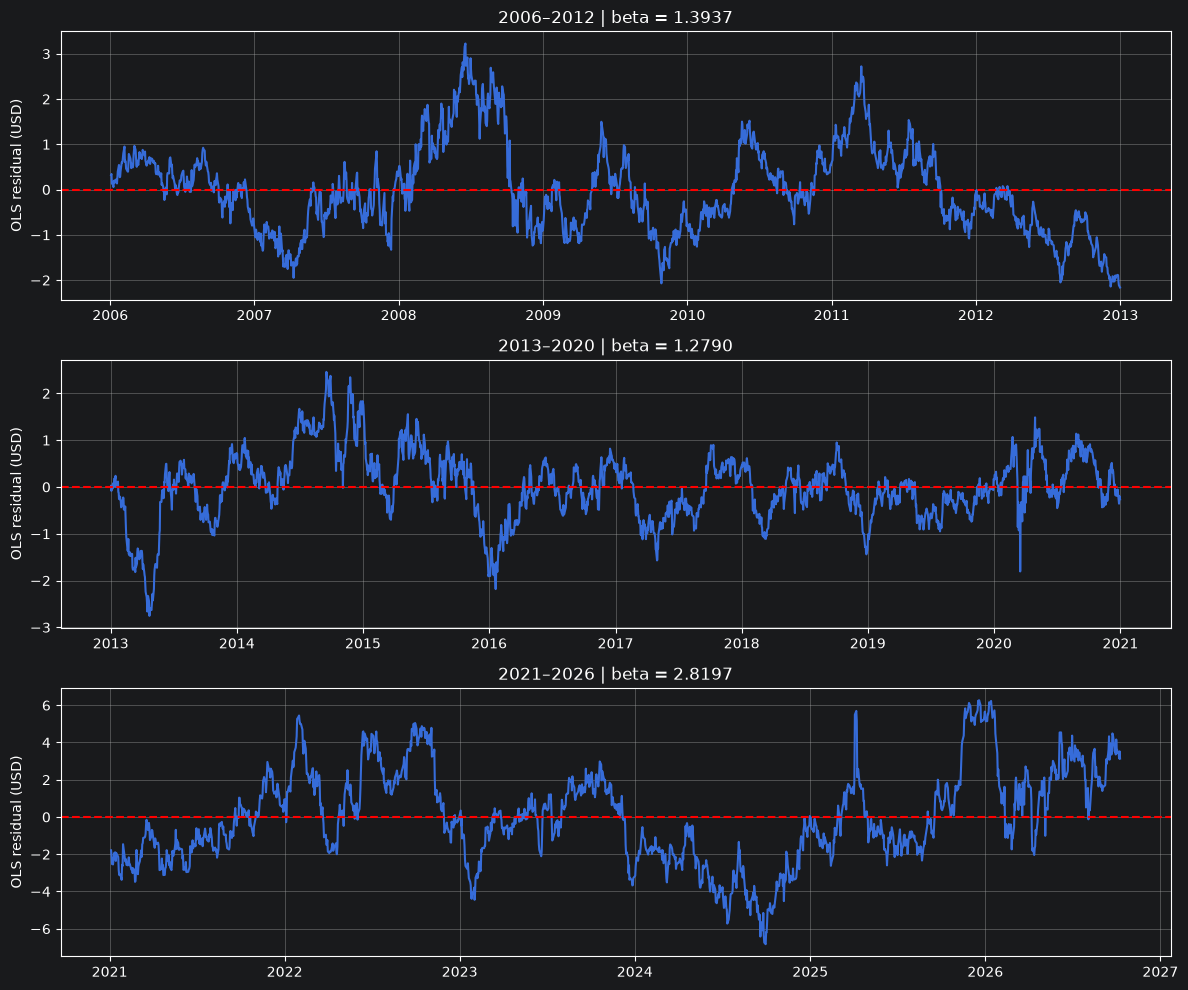

In [15]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10))

for ax, (name, period) in zip(axes, periods.items()):

    # Estimate OLS separately for each period
    X = sm.add_constant(period["EWA"])
    model = sm.OLS(period["EWC"], X).fit()

    alpha_period = model.params["const"]
    beta_period = model.params["EWA"]

    # Compute the OLS residual spread
    spread_period = (
        period["EWC"]
        - alpha_period
        - beta_period * period["EWA"]
    )

    print(f"{name}: alpha = {alpha_period:.4f}, "
          f"beta = {beta_period:.4f}")

    ax.plot(spread_period.index, spread_period)
    ax.axhline(0, color="red", linestyle="--")
    ax.set_title(f"{name} | beta = {beta_period:.4f}")
    ax.set_ylabel("OLS residual (USD)")
    ax.grid(True)

plt.tight_layout()
plt.show()

In [17]:
import numpy as np
import pandas as pd
import statsmodels.api as sm

# Only use the training period (2006-2012)
train_spread = spread.loc[train.index].dropna()

# Construct variables for the regression
regression_data = pd.DataFrame({
    "spread_lag": train_spread.shift(1),
    "delta_spread": train_spread.diff()
}).dropna()

# OLS: delta_S(t) = mu + lambda * S(t-1) + epsilon(t)
X = sm.add_constant(regression_data["spread_lag"])
y = regression_data["delta_spread"]

half_life_model = sm.OLS(y, X).fit()

# Estimated parameters
mu_hat = half_life_model.params["const"]
lambda_hat = half_life_model.params["spread_lag"]

print(f"Mu: {mu_hat:.6f}")
print(f"Lambda: {lambda_hat:.6f}")

# Calculate half-life, following Chan
if -1 < lambda_hat < 0:
    half_life = -np.log(2) / lambda_hat
    lookback = max(2, round(half_life))

    equilibrium = -mu_hat / lambda_hat

    print(f"Half-life: {half_life:.2f} trading days")
    print(f"Lookback: {lookback} trading days")
    print(f"Estimated equilibrium: {equilibrium:.4f}")

else:
    half_life = None
    lookback = None
    print("No conventional positive half-life: inspect lambda.")

print(half_life_model.summary())

Mu: 0.064956
Lambda: -0.017273
Half-life: 40.13 trading days
Lookback: 40 trading days
Estimated equilibrium: 3.7604
                            OLS Regression Results                            
Dep. Variable:           delta_spread   R-squared:                       0.008
Model:                            OLS   Adj. R-squared:                  0.007
Method:                 Least Squares   F-statistic:                     14.18
Date:                Sun, 11 Oct 2026   Prob (F-statistic):           0.000171
Time:                        08:55:56   Log-Likelihood:                 448.56
No. Observations:                1760   AIC:                            -893.1
Df Residuals:                    1758   BIC:                            -882.2
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
--------------

In [18]:
# Step 5: Construct trading signals

# Fixed parameters from training period
# beta and lookback were estimated in steps 2 and 4

signals = pd.DataFrame(index=prices.index)

# Spread using the fixed hedge ratio
signals["spread"] = prices["EWC"] - beta * prices["EWA"]

# Rolling statistics
signals["moving_average"] = (
    signals["spread"].rolling(window=lookback).mean()
)

signals["moving_std"] = (
    signals["spread"].rolling(window=lookback).std()
)

# Z-score
signals["z_score"] = (
    (signals["spread"] - signals["moving_average"])
    / signals["moving_std"]
)

# Linear mean-reversion strategy
signals["num_units"] = -signals["z_score"]

print(signals.loc["2013":].head())

              spread  moving_average  moving_std   z_score  num_units
Date                                                                 
2013-01-02  1.764364        2.034769    0.229466 -1.178412   1.178412
2013-01-03  1.662572        2.011001    0.216899 -1.606408   1.606408
2013-01-04  1.696849        1.991931    0.209861 -1.406081   1.406081
2013-01-07  1.714406        1.976386    0.206712 -1.267367   1.267367
2013-01-08  1.832724        1.966926    0.204339 -0.656763   0.656763


In [19]:
# Step 5: Construct trading signals

# Fixed parameters from training period
# beta and lookback were estimated in steps 2 and 4

signals = pd.DataFrame(index=prices.index)

# Spread using the fixed hedge ratio
signals["spread"] = prices["EWC"] - beta * prices["EWA"]

# Rolling statistics
signals["moving_average"] = (
    signals["spread"].rolling(window=lookback).mean()
)

signals["moving_std"] = (
    signals["spread"].rolling(window=lookback).std()
)

# Z-score
signals["z_score"] = (
    (signals["spread"] - signals["moving_average"])
    / signals["moving_std"]
)

# Linear mean-reversion strategy
signals["num_units"] = -signals["z_score"]

print(signals.loc["2013":].head())

              spread  moving_average  moving_std   z_score  num_units
Date                                                                 
2013-01-02  1.764364        2.034769    0.229466 -1.178412   1.178412
2013-01-03  1.662572        2.011001    0.216899 -1.606408   1.606408
2013-01-04  1.696849        1.991931    0.209861 -1.406081   1.406081
2013-01-07  1.714406        1.976386    0.206712 -1.267367   1.267367
2013-01-08  1.832724        1.966926    0.204339 -0.656763   0.656763


In [23]:
# Number of shares in each ETF
shares = pd.DataFrame(index=prices.index)

shares["EWC"] = signals["num_units"]
shares["EWA"] = -beta * signals["num_units"]

# Dollar value of each position
positions = shares * prices[["EWC", "EWA"]]

# Gross dollar exposure
signals["gross_exposure"] = positions.abs().sum(
    axis=1, min_count=1
)

print("Number of shares:")
print(shares.loc["2013":].head())

print("\nDollar positions:")
print(positions.loc["2013":].head())

Number of shares:
                 EWC       EWA
Date                          
2013-01-02  1.178412 -1.642331
2013-01-03  1.606408 -2.238821
2013-01-04  1.406081 -1.959629
2013-01-07  1.267367 -1.766305
2013-01-08  0.656763 -0.915319

Dollar positions:
                  EWC        EWA
Date                            
2013-01-02  25.650137 -23.570990
2013-01-03  34.651419 -31.980649
2013-01-04  30.499775 -28.113868
2013-01-07  27.433566 -25.260785
2013-01-08  14.206470 -13.002804


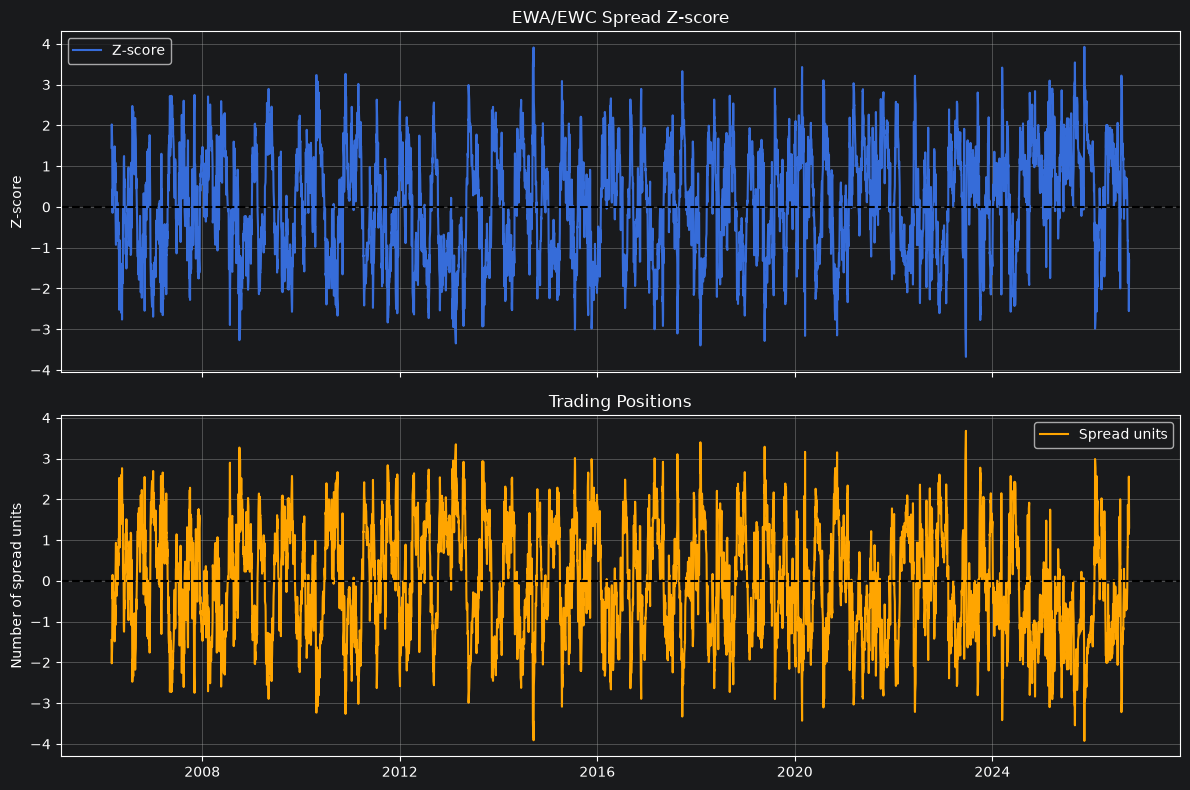

In [25]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# Z-score
axes[0].plot(
    signals.index,
    signals["z_score"],
    label="Z-score"
)

axes[0].axhline(0, color="black", linestyle="--")
axes[0].set_title("EWA/EWC Spread Z-score")
axes[0].set_ylabel("Z-score")
axes[0].legend()
axes[0].grid(True)

# Number of spread units
axes[1].plot(
    signals.index,
    signals["num_units"],
    color="orange",
    label="Spread units"
)

axes[1].axhline(0, color="black", linestyle="--")
axes[1].set_title("Trading Positions")
axes[1].set_ylabel("Number of spread units")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [26]:
# Step 6: Backtesting the trading strategy

# Daily price changes
price_changes = prices[["EWC", "EWA"]].diff()

# Positions from the previous trading day
previous_shares = shares.shift(1)

# Daily profit and loss (USD)
daily_pnl = (
    previous_shares * price_changes
).sum(axis=1, min_count=2)

# Previous day's gross portfolio value
previous_gross_exposure = (
    positions.abs().sum(axis=1, min_count=2).shift(1)
)

# Daily returns, following Chan
daily_returns = daily_pnl / previous_gross_exposure.where(
    previous_gross_exposure > 1e-12
)

# Construct the backtest DataFrame
backtest = pd.DataFrame({
    "pnl": daily_pnl,
    "gross_exposure": previous_gross_exposure,
    "return": daily_returns
}).dropna(subset=["return"])

# Split into in-sample and out-of-sample periods
train_bt = backtest.loc[:"2012-12-31"].copy()
test_bt = backtest.loc["2013-01-01":].copy()

print(test_bt.head())

                 pnl  gross_exposure    return
Date                                          
2013-01-02  0.131312       61.995028  0.002118
2013-01-03 -0.119952       49.221127 -0.002437
2013-01-04  0.055062       66.632068  0.000826
2013-01-07  0.024687       58.613643  0.000421
2013-01-08  0.149952       52.694351  0.002846


In [27]:
def performance_metrics(returns):
    r = returns.dropna()

    # Cumulative return index
    equity = (1 + r).cumprod()

    # Drawdown
    running_max = equity.cummax()
    drawdown = equity / running_max - 1

    # Annualized performance
    apr = r.mean() * 252
    volatility = r.std() * np.sqrt(252)
    sharpe = apr / volatility if volatility > 0 else np.nan

    # Annualized compounded growth
    cagr = equity.iloc[-1] ** (252 / len(r)) - 1

    return pd.Series({
        "APR": apr,
        "CAGR": cagr,
        "Annual volatility": volatility,
        "Sharpe": sharpe,
        "Max drawdown": drawdown.min()
    })


# Compare in-sample and out-of-sample performance
results = pd.DataFrame({
    "2006-2012 (IS)": performance_metrics(train_bt["return"]),
    "2013-2026 (OOS)": performance_metrics(test_bt["return"])
}).T

print(results.round(4))

                    APR    CAGR  Annual volatility  Sharpe  Max drawdown
2006-2012 (IS)   0.0577  0.0544             0.0978  0.5903       -0.2081
2013-2026 (OOS)  0.0371  0.0358             0.0626  0.5931       -0.1725


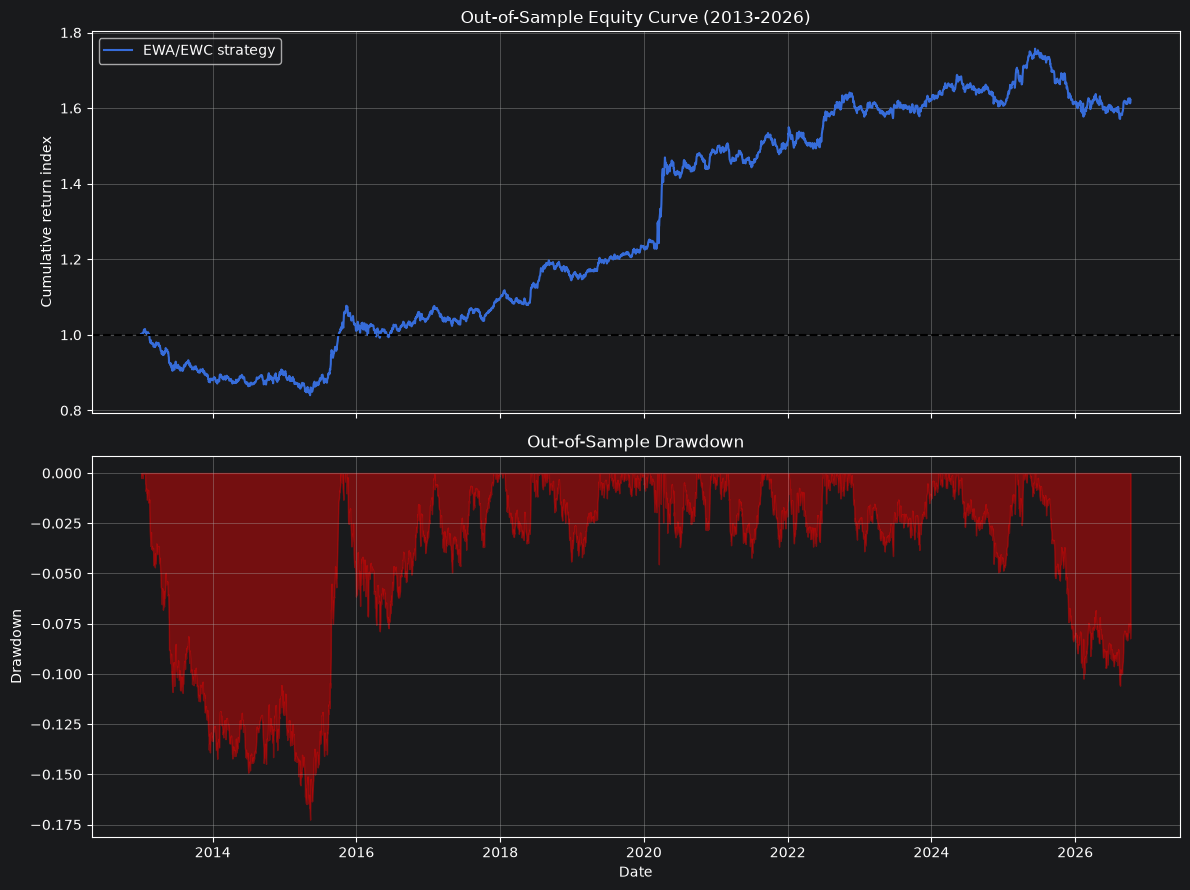

In [28]:
# Out-of-sample cumulative return index
test_bt["equity_curve"] = (
    1 + test_bt["return"]
).cumprod()

# Drawdown
test_bt["running_max"] = test_bt["equity_curve"].cummax()

test_bt["drawdown"] = (
    test_bt["equity_curve"] / test_bt["running_max"] - 1
)

# Plot
fig, axes = plt.subplots(
    2, 1, figsize=(12, 9), sharex=True
)

# Cumulative returns
axes[0].plot(
    test_bt.index,
    test_bt["equity_curve"],
    label="EWA/EWC strategy"
)

axes[0].axhline(1, color="black", linestyle="--")

axes[0].set_title("Out-of-Sample Equity Curve (2013-2026)")
axes[0].set_ylabel("Cumulative return index")
axes[0].legend()
axes[0].grid(True)

# Drawdown
axes[1].fill_between(
    test_bt.index,
    test_bt["drawdown"],
    0,
    color="red",
    alpha=0.4
)

axes[1].set_title("Out-of-Sample Drawdown")
axes[1].set_ylabel("Drawdown")
axes[1].set_xlabel("Date")
axes[1].grid(True)

plt.tight_layout()
plt.show()

Date
2013   -12.00
2014     1.51
2015    13.32
2016     3.00
2017     5.15
2018     4.63
2019     7.19
2020    20.53
2021     2.02
2022     5.87
2023     1.46
2024    -1.10
2025     0.58
2026     0.39
Name: return, dtype: float64


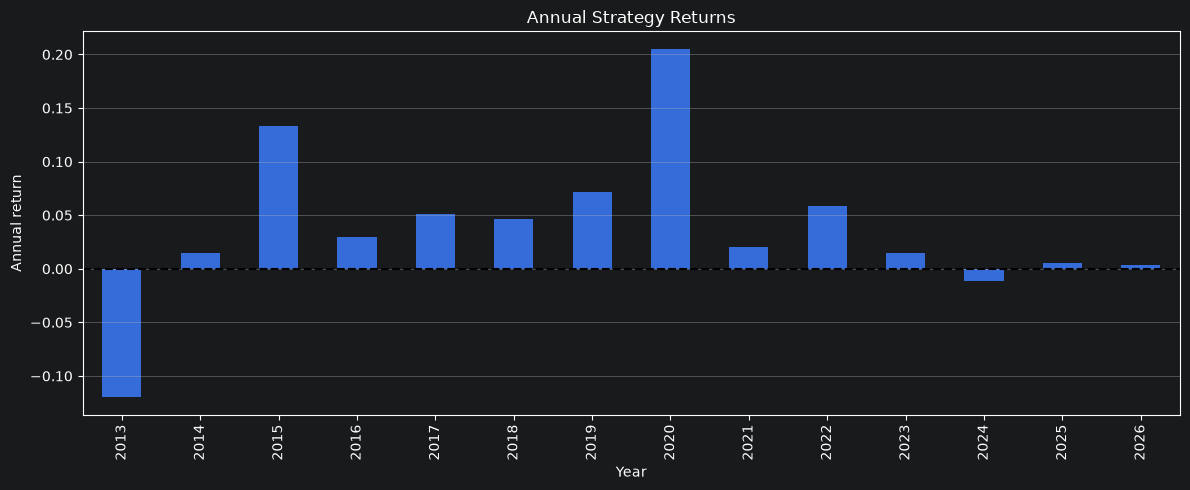

In [29]:
annual_returns = (
    (1 + test_bt["return"])
    .resample("YE")
    .prod() - 1
)

annual_returns.index = annual_returns.index.year

print((annual_returns * 100).round(2))

plt.figure(figsize=(12, 5))

annual_returns.plot.bar()

plt.axhline(0, color="black", linestyle="--")
plt.title("Annual Strategy Returns")
plt.xlabel("Year")
plt.ylabel("Annual return")
plt.grid(axis="y")
plt.tight_layout()
plt.show()